*Import Libraries*

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

load data

In [36]:
df = pd.read_csv("listings - Copy.csv")
print(df.shape)                # expect (8704, 21)
df.info()

(8704, 19)
<class 'pandas.DataFrame'>
RangeIndex: 8704 entries, 0 to 8703
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              8704 non-null   int64  
 1   name                            8704 non-null   str    
 2   host_id                         8660 non-null   float64
 3   host_profile_id                 8612 non-null   float64
 4   host_name                       8616 non-null   str    
 5   neighbourhood_group             0 non-null      float64
 6   neighbourhood                   8704 non-null   str    
 7   latitude                        8704 non-null   float64
 8   longitude                       8704 non-null   float64
 9   room_type                       8704 non-null   str    
 10  price                           7645 non-null   float64
 11  minimum_nights                  8700 non-null   float64
 12  number_of_reviews               87

In [37]:
df["last_review"] = pd.to_datetime(df["last_review"], errors="coerce")
for c in ["price", "minimum_nights", "availability_365", "number_of_reviews",
          "number_of_reviews_ltm", "reviews_per_month",
          "calculated_host_listings_count"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

In [38]:
nulls = df.isnull().sum().to_frame("nulls")
nulls["pct"] = (nulls["nulls"] / len(df) * 100).round(2)
print(nulls[nulls["nulls"] > 0].sort_values("nulls", ascending=False))

                                nulls     pct
neighbourhood_group              8704  100.00
license                          2938   33.75
last_review                      1525   17.52
reviews_per_month                1525   17.52
price                            1059   12.17
host_profile_id                    92    1.06
host_name                          88    1.01
host_id                            44    0.51
calculated_host_listings_count     44    0.51
minimum_nights                      4    0.05


In [39]:
print("Duplicate IDs:", df["id"].duplicated().sum())
df = df.drop_duplicates(subset="id")

Duplicate IDs: 0


In [40]:

df["license"] = df["license"].fillna("Not Available")
df["host_name"] = df["host_name"].fillna("Unknown")
df["name"] = df["name"].fillna("Unknown")
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)      # no reviews = 0
df["number_of_reviews_ltm"] = df["number_of_reviews_ltm"].fillna(0)
df["number_of_reviews"] = df["number_of_reviews"].fillna(0)
df["availability_365"] = df["availability_365"].fillna(df["availability_365"].median())
df["minimum_nights"] = df["minimum_nights"].fillna(df["minimum_nights"].median())


In [41]:
if "price_imputed" not in df.columns:
    df["price_imputed"] = 0
df["price_imputed"] = df["price_imputed"].fillna(0).astype(int)

keys = ["neighbourhood_group", "room_type"]


In [42]:

#  neighbourhood_group from neighbourhood

group_map = {
    "Central": ["Loop", "Near North Side", "Near South Side"],
    "Far North Side": ["Albany Park", "Edgewater", "Edison Park", "Forest Glen",
                       "Jefferson Park", "Lincoln Square", "North Park", "Norwood Park",
                       "Ohare", "Rogers Park", "Uptown", "West Ridge"],
    "Far Southeast Side": ["Avalon Park", "Burnside", "Calumet Heights", "Chatham",
                           "East Side", "Hegewisch", "Pullman", "Riverdale", "Roseland",
                           "South Chicago", "South Deering", "West Pullman"],
    "Far Southwest Side": ["Ashburn", "Auburn Gresham", "Beverly", "Morgan Park",
                           "Mount Greenwood", "Washington Heights"],
    "North Side": ["Avondale", "Lake View", "Lincoln Park", "Logan Square", "North Center"],
    "Northwest Side": ["Belmont Cragin", "Dunning", "Hermosa", "Irving Park",
                       "Montclare", "Portage Park"],
    "South Side": ["Armour Square", "Bridgeport", "Douglas", "Fuller Park", "Grand Boulevard",
                   "Greater Grand Crossing", "Hyde Park", "Kenwood", "Oakland", "South Shore",
                   "Washington Park", "Woodlawn"],
    "Southwest Side": ["Archer Heights", "Brighton Park", "Chicago Lawn", "Clearing",
                       "Englewood", "Gage Park", "Garfield Ridge", "Mckinley Park", "New City",
                       "West Elsdon", "West Englewood", "West Lawn"],
    "West Side": ["Austin", "East Garfield Park", "Humboldt Park", "Lower West Side",
                  "Near West Side", "North Lawndale", "South Lawndale",
                  "West Garfield Park", "West Town"],
}

# flip {group: [neighbourhoods]} into {neighbourhood: group}
hood_to_group = {hood: grp for grp, hoods in group_map.items() for hood in hoods}

df["neighbourhood"] = df["neighbourhood"].str.strip().str.title()
df["neighbourhood_group"] = df["neighbourhood"].map(hood_to_group)

# every neighbourhood must be mapped
print("Unmapped rows:", df["neighbourhood_group"].isna().sum())
print(df["neighbourhood_group"].value_counts())

Unmapped rows: 0
neighbourhood_group
West Side             2049
Central               1900
North Side            1555
South Side            1238
Far North Side         991
Northwest Side         453
Southwest Side         253
Far Southeast Side     164
Far Southwest Side     101
Name: count, dtype: int64


In [43]:
#fill the price
keys = ["neighbourhood_group", "room_type"]     # all lowercase

df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["price_imputed"] = df["price_imputed"].fillna(0).astype(int)

# 1) IQR bounds per group (transform keeps the original row order, no merge needed)
q1 = df.groupby(keys)["price"].transform(lambda s: s.quantile(0.25))
q3 = df.groupby(keys)["price"].transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
df["lower"] = q1 - 1.5 * iqr
df["upper"] = q3 + 1.5 * iqr

# 2) Flag outliers
df["price_outlier"] = (df["price"] < df["lower"]) | (df["price"] > df["upper"])
print("Price outliers:", df["price_outlier"].sum(),
      "| Missing price:", df["price"].isna().sum())

# 3) Fill values from NON-outlier prices only
ok = df["price"].notna() & ~df["price_outlier"]
grp_med = df[ok].groupby(keys)["price"].median().rename("grp_med")
rt_med = df[ok].groupby("room_type")["price"].median().rename("rt_med")

df = df.join(grp_med, on=keys).join(rt_med, on="room_type")

# Fallback chain: group median -> room type median -> overall median
df["fill_value"] = (df["grp_med"]
                    .fillna(df["rt_med"])
                    .fillna(df.loc[ok, "price"].median()))

# 4) Replace missing + outlier prices and flag them
needs_fix = df["price"].isna() | df["price_outlier"]
df["price_outlier_fixed"] = needs_fix.astype(int)   # separate flag: newly fixed rows
df.loc[needs_fix, "price_imputed"] = 1
df.loc[needs_fix, "price"] = df.loc[needs_fix, "fill_value"]

df = df.drop(columns=["lower", "upper", "grp_med", "rt_med", "fill_value", "price_outlier"])

print("Rows fixed by IQR:", df["price_outlier_fixed"].sum())
print("Rows with imputed price (total):", df["price_imputed"].sum())
print(df["price"].describe().round(2))

Price outliers: 556 | Missing price: 1059
Rows fixed by IQR: 1615
Rows with imputed price (total): 1615
count    8704.00
mean      243.68
std       150.95
min         3.00
25%       135.00
50%       224.00
75%       306.00
max       986.00
Name: price, dtype: float64


In [44]:
#fill the license
def check(x):
    if x == "Not Available":          # the filled nulls (must match the text exactly)
        return "no license"
    if x.startswith("R") and len(x) == 12 and x[1:].isdigit() and x[3:6] == "000":
        return "valid"                # R code, like R23000105602
    if x.isdigit() and len(x) == 7:
        return "valid"                # number, like 2792126
    return "not valid"                # wrong format

df["license_status"] = df["license"].apply(check)
print(df["license_status"].value_counts())

license_status
valid         5737
no license    2938
not valid       29
Name: count, dtype: int64


In [45]:
today = pd.Timestamp.today().normalize()
df["booked_days"] = (365 - df["availability_365"]).clip(0, 365)
df["occupancy_pct"] = (df["booked_days"] / 365 * 100).round(1)
df["est_annual_revenue"] = df["price"] * df["booked_days"]
df["days_since_last_review"] = (today - df["last_review"]).dt.days

In [46]:
#find demads
demand_group = (df.groupby("neighbourhood_group")
    .agg(listings=("id", "count"),
         avg_price=("price", "mean"),
         avg_occupancy=("occupancy_pct", "mean"),
         avg_reviews_pm=("reviews_per_month", "mean"),
         total_revenue=("est_annual_revenue", "sum"))
    .round(2).sort_values("total_revenue", ascending=False))
print(demand_group)

                     listings  avg_price  avg_occupancy  avg_reviews_pm  \
neighbourhood_group                                                       
Central                  1900     332.49          34.75            1.36   
West Side                2049     241.21          40.34            1.57   
North Side               1555     270.58          46.46            1.96   
South Side               1238     174.66          37.93            1.26   
Far North Side            991     195.42          43.48            1.84   
Northwest Side            453     193.16          40.40            1.51   
Southwest Side            253     121.79          42.36            1.21   
Far Southeast Side        164     175.56          39.20            0.82   
Far Southwest Side        101     170.80          38.85            1.13   

                     total_revenue  
neighbourhood_group                 
Central                 78558284.0  
West Side               70080291.0  
North Side              68

In [47]:
#  Demand by room type
demand_room = (df.groupby("room_type")
    .agg(listings=("id", "count"), avg_price=("price", "mean"),
         avg_occupancy=("occupancy_pct", "mean"),
         avg_reviews_pm=("reviews_per_month", "mean")).round(2))
print(demand_room)

                 listings  avg_price  avg_occupancy  avg_reviews_pm
room_type                                                          
Entire home/apt      6663     278.63          39.72            1.65
Hotel room             70     411.36          50.30            0.52
Private room         1939     120.75          41.70            1.24
Shared room            32      47.78          40.12            0.68


In [48]:
top_nb = (df.groupby("neighbourhood")
    .agg(listings=("id", "count"), avg_occupancy=("occupancy_pct", "mean"),
         avg_price=("price", "mean"), avg_reviews_pm=("reviews_per_month", "mean"))
    .query("listings >= 30").round(2)
    .sort_values("avg_occupancy", ascending=False).head(15))
print(top_nb)

                 listings  avg_occupancy  avg_price  avg_reviews_pm
neighbourhood                                                      
New City               49          58.14      95.14            0.97
Englewood              50          55.39     100.92            1.44
South Chicago          43          50.22     100.60            0.54
Jefferson Park         59          49.17     186.39            1.68
Lower West Side       240          48.99     208.25            2.03
Logan Square          408          48.15     227.91            1.85
Hyde Park             137          47.88     163.63            1.79
Lincoln Square        113          47.14     207.52            2.37
Lincoln Park          286          46.68     315.10            1.80
Avondale              191          46.67     214.38            1.95
Rogers Park           172          46.10     186.12            1.62
Lake View             537          45.85     298.03            2.23
Portage Park          113          45.73     186

In [49]:
df["min_night_bucket"] = pd.cut(df["minimum_nights"], [0, 1, 2, 6, 29, np.inf],
    labels=["1", "2", "3-6", "7-29", "30+"])
df["price_band"] = pd.qcut(df["price"], 4, labels=["Low", "Mid", "High", "Premium"])
for col in ["min_night_bucket", "price_band"]:
    print(df.groupby(col, observed=True)
            .agg(listings=("id", "count"), avg_occupancy=("occupancy_pct", "mean"),
                 avg_reviews_pm=("reviews_per_month", "mean")).round(2))

                  listings  avg_occupancy  avg_reviews_pm
min_night_bucket                                         
1                      384          38.68            2.39
2                     4779          41.05            2.29
3-6                    521          48.11            1.41
7-29                   112          55.58            0.55
30+                   2908          37.14            0.27
            listings  avg_occupancy  avg_reviews_pm
price_band                                         
Low             2188          41.93            0.95
Mid             2166          42.13            1.94
High            2331          42.02            1.45
Premium         2019          34.38            1.89


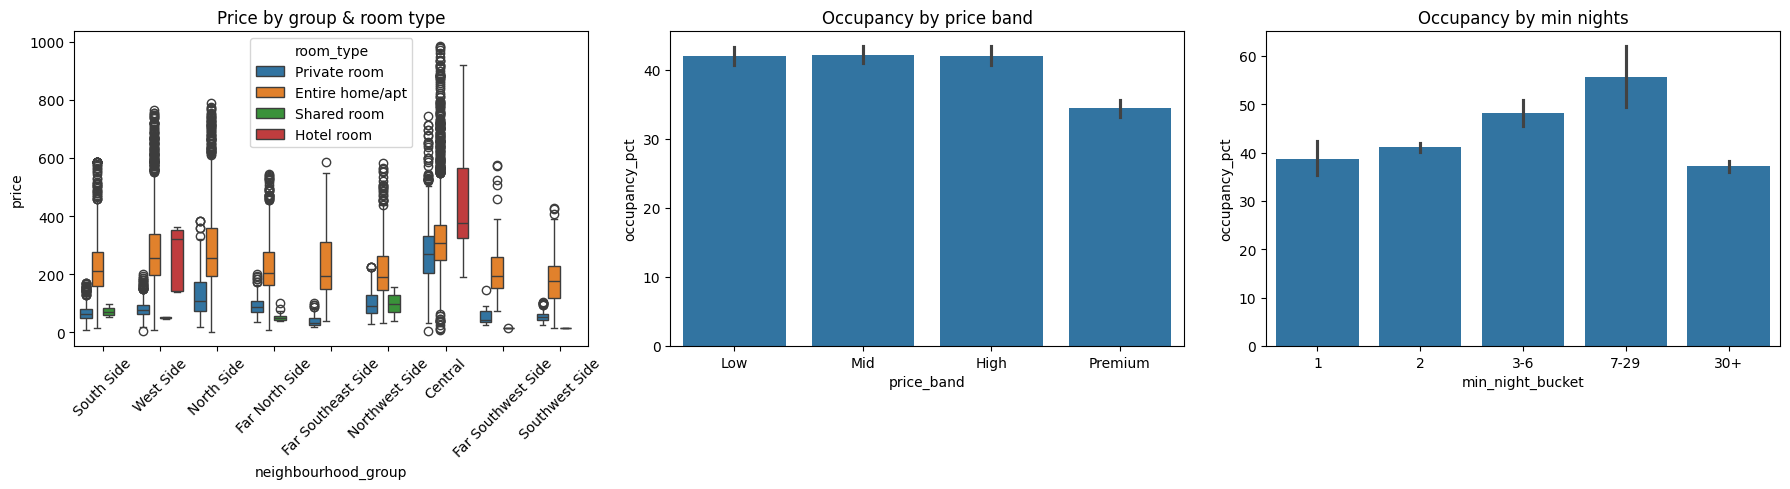

In [50]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x="neighbourhood_group", y="price", hue="room_type", ax=ax[0])
ax[0].tick_params(axis="x", rotation=45); ax[0].set_title("Price by group & room type")
sns.barplot(data=df, x="price_band", y="occupancy_pct", ax=ax[1]); ax[1].set_title("Occupancy by price band")
sns.barplot(data=df, x="min_night_bucket", y="occupancy_pct", ax=ax[2]); ax[2].set_title("Occupancy by min nights")
plt.tight_layout(); plt.show()

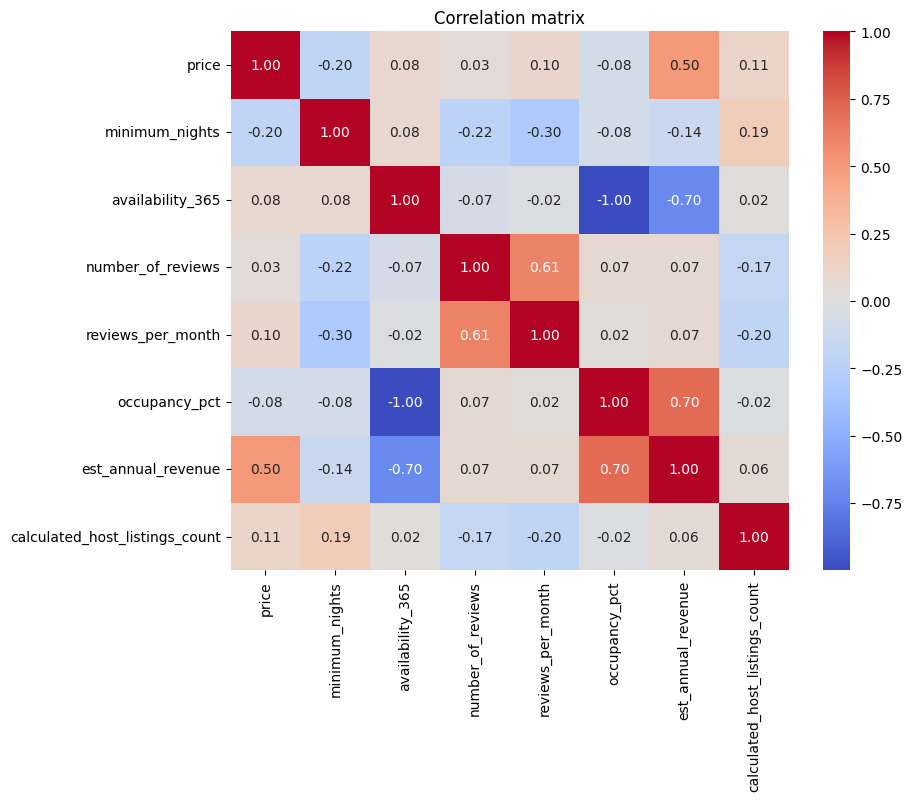

In [51]:
#  Correlation
num_cols = ["price", "minimum_nights", "availability_365", "number_of_reviews",
            "reviews_per_month", "occupancy_pct", "est_annual_revenue",
            "calculated_host_listings_count"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix"); plt.show()

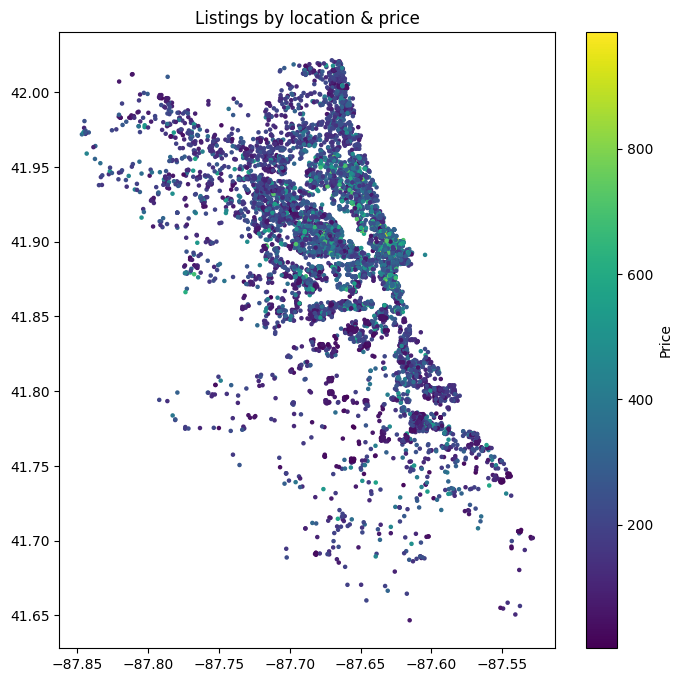

In [52]:
plt.figure(figsize=(8, 8))
sc = plt.scatter(df["longitude"], df["latitude"], c=df["price"], s=5, cmap="viridis")
plt.colorbar(sc, label="Price"); plt.title("Listings by location & price"); plt.show()

,neighbourhood,listings,median_price,reviews_ltm,quadrant,score
0,South Lawndale,51,151.0,20.6,Opportunity,82.2
1,Englewood,50,63.0,13.8,Opportunity,70.4
2,Armour Square,85,136.0,17.1,Opportunity,70.0
3,Lincoln Square,113,194.0,26.0,Opportunity,69.7
4,Jefferson Park,59,164.0,16.7,Opportunity,67.1
5,East Garfield Park,104,136.5,16.9,Opportunity,66.7
6,Dunning,43,192.0,13.4,Watch,62.2
7,Uptown,166,205.5,24.5,Established,62.2
8,Portage Park,113,159.0,16.8,Opportunity,60.9
9,Albany Park,81,169.0,16.1,Opportunity,60.3


quadrant
Watch          14
Established    14
Opportunity     8
Saturated       8
Name: count, dtype: int64

Top 5: South Lawndale, Englewood, Armour Square, Lincoln Square, Jefferson Park
Correlation price vs supply: 0.66


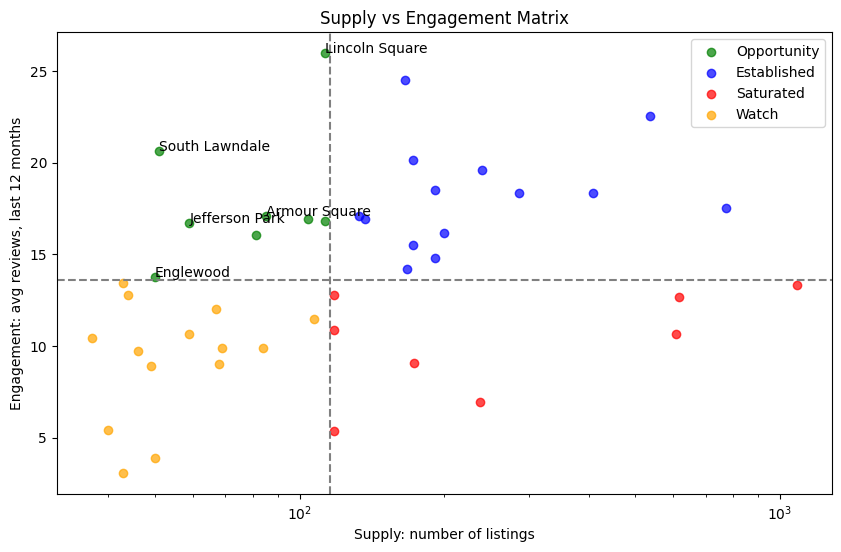

In [53]:
# Supply vs Engagement Matrix (simple version, for your notebook)
# Assumes your cleaned data is already loaded as `df`

MIN_LISTINGS = 30

# 1. One row per neighborhood
nb = df.groupby("neighbourhood").agg(
    listings=("id", "count"),
    median_price=("price", "median"),
    reviews_ltm=("number_of_reviews_ltm", "mean"),
).reset_index()
nb = nb[nb["listings"] >= MIN_LISTINGS]

# 2. Quadrants: split at the median
supply_cut = nb["listings"].median()
engage_cut = nb["reviews_ltm"].median()

def quadrant(r):
    low_supply = r["listings"] < supply_cut
    strong = r["reviews_ltm"] >= engage_cut
    if low_supply and strong:
        return "Opportunity"
    if strong:
        return "Established"
    if not low_supply:
        return "Saturated"
    return "Watch"

nb["quadrant"] = nb.apply(quadrant, axis=1)

# 3. Opportunity score (0-100): low supply 35%, engagement 45%, low price 20%
nb["score"] = 100 * (
    0.35 * (1 - nb["listings"].rank(pct=True))
    + 0.45 * nb["reviews_ltm"].rank(pct=True)
    + 0.20 * (1 - nb["median_price"].rank(pct=True))
)
nb = nb.sort_values("score", ascending=False).reset_index(drop=True)

# 4. Results
display(nb.round(1))
print(nb["quadrant"].value_counts())
print("\nTop 5:", ", ".join(nb["neighbourhood"].head(5)))
print("Correlation price vs supply:",
      round(nb["median_price"].corr(nb["listings"], method="spearman"), 2))

# 5. Chart
colors = {"Opportunity": "green", "Established": "blue",
          "Saturated": "red", "Watch": "orange"}
plt.figure(figsize=(10, 6))
for q, c in colors.items():
    s = nb[nb["quadrant"] == q]
    plt.scatter(s["listings"], s["reviews_ltm"], c=c, label=q, alpha=0.7)
for _, r in nb.head(5).iterrows():
    plt.annotate(r["neighbourhood"], (r["listings"], r["reviews_ltm"]))
plt.axvline(supply_cut, ls="--", c="grey")
plt.axhline(engage_cut, ls="--", c="grey")
plt.xscale("log")
plt.xlabel("Supply: number of listings")
plt.ylabel("Engagement: avg reviews, last 12 months")
plt.title("Supply vs Engagement Matrix")
plt.legend()
plt.show()